# CS-430 Machine Learning: Assignment 2
## Nikoa Mrdak

## Part 1 – Get to Know the Prediction Problem (15 points)
1. Load the dataset and examine its structure.
- Load the CSV file into pandas.
- Display the first 5 rows.
- Report the number of rows and columns.
- Print the column names.
- Use info() to inspect the dataset.

Answer:
- Which variable will be the target?
- Which columns appear to be numerical?
- Which columns appear to be categorical?

In [1]:
#Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor, Lasso
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error


In [2]:
#Import Data
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Assignment2/SLCM_rent_arrears_student_clean.csv')
data.head(5)

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [3]:
print(f'This dataset has {data.shape[0]} rows and {data.shape[1]} columns')
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(f'Column Names: {data.columns}')
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data.info())

This dataset has 1754 rows and 14 columns
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Column Names: Index(['record_id', 'adults_in_household', 'children_in_household',
       'household_has_65plus', 'monthly_household_income', 'income_sources',
       'employment_status', 'has_housing_voucher', 'eviction_in_progress',
       'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter',
       'monthly_rent', 'past_due_rent'],
      dtype='object')
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null 

Target:
- 13  past_due_rent              ~ 1754 non-null   float64

Numerical:  
- 1   adults_in_household        ~ 1754 non-null   int64  
- 2   children_in_household      ~ 1754 non-null   int64   
- 4   monthly_household_income   ~ 1646 non-null   float64
- 12  monthly_rent               ~ 1746 non-null   float64

 Categorical:
- 0   record_id              ~ 1754 non-null   object
- 3   household_has_65plus   ~ 1754 non-null   object
- 5   income_sources         ~ 1754 non-null   object
- 6   employment_status       ~ 1754 non-null   object
- 7   has_housing_voucher      ~ 1754 non-null   object
- 8   eviction_in_progress      ~ 1753 non-null   object
- 9   behind_on_utilities        ~ 1747 non-null   object
- 10  main_reason_behind_on_rent  ~ 1738 non-null   object
- 11  intake_quarter              ~ 1754 non-null   object


2. Investigate missing values.- Calculate the number of missing values in every column.
- Identify which variables contain missing data.
- Briefly describe how you plan to handle those missing values before modeling.
Do not simply remove all rows with missing data unless you can justify that decision.

In [4]:
data.isnull().sum().sort_values(ascending=False)

,0
monthly_household_income,108
main_reason_behind_on_rent,16
monthly_rent,8
behind_on_utilities,7
eviction_in_progress,1
record_id,0
income_sources,0
household_has_65plus,0
children_in_household,0
adults_in_household,0


For the relatively small number of values for most of the columns, dropping them will not significantly affect modeling. For the 108 missing values in monthly_household_income, I plan to imput the average income by income source. My reason for this is to preserve these rows while imputing incomes that are close to the true missing values.

3. Explore the target variable: past_due_rent.
Calculate:
- count
- mean
- median
- standard deviation
- minimum
- maximum

Create:
- a histogram
- a boxplot
Answer:
- What does the distribution look like?
- Is the distribution symmetric or skewed?
- Are the mean and median similar?
- Do you notice any unusually high values?
- Why might rent-arrears data naturally contain a wide range of values?
Do not automatically remove an observation simply because it is high.

In [5]:
data['past_due_rent'].describe()

,past_due_rent
count,1754.000000
mean,2408.006933
std,2089.515372
min,0.000000
25%,1050.000000
50%,2000.000000
75%,3200.000000
max,20000.000000


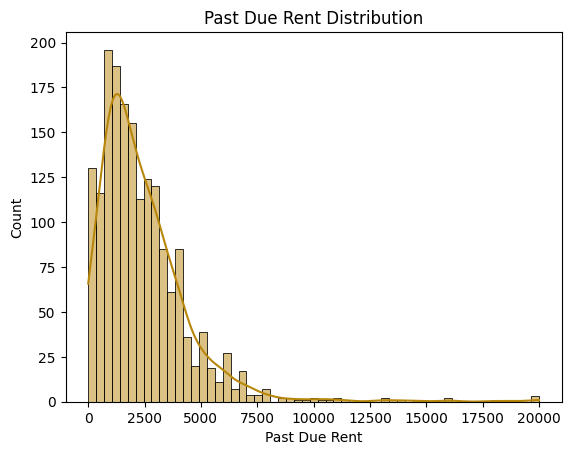

In [6]:
#Histplot
sns.histplot(data['past_due_rent'], kde = True, color = 'darkgoldenrod')
plt.xlabel('Past Due Rent')
plt.ylabel('Count')
plt.title('Past Due Rent Distribution')

plt.show()
#Right skewed

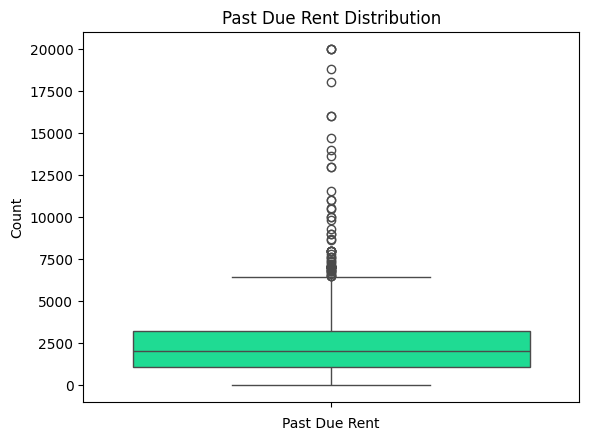

In [7]:
#Boxplot
sns.boxplot(data['past_due_rent'], color = 'mediumspringgreen')
plt.xlabel('Past Due Rent')
plt.ylabel('Count')
plt.title('Past Due Rent Distribution')

plt.show()

In [8]:
data['monthly_rent'].describe()

,monthly_rent
count,1746.000000
mean,967.054750
std,451.094487
min,0.000000
25%,720.000000
50%,975.000000
75%,1200.750000
max,4300.000000


The distribution of past due rent is clearly right skewed. With a median of 2000 and a mean of 2400, the majority of observations are behind no more than 3200 dollars. This dataset contains a lot of outliers, however, with numerous outliers surpasing over 5000 and a max of 20000.

Everyone pays different amounts for rent, which helps explain the variety of behind rent amounts. But with a mean monthly rent amount of 967 dollars, it is a plausable explination that a large number of observations become behind on two months of rent to sum near the median of 2000 dollars behind on rent.

## Part 2 – Prepare the Data for Machine Learning (25 points)
4. Create your input features and target.
Create X and y using past_due_rent as the target. Do not use record_id as an input feature.
Answer:
- Why should record_id not be used to predict past-due rent?

In [9]:
X = data.drop(columns = ['record_id', 'intake_quarter', 'past_due_rent'], axis = 1)
y = data['past_due_rent']

It is important not to include record_id as a variable in the training set because it only counts each observation. If included, the model may find false significance in the variable that does not measurse anything. Furthermore, intake_quarter is a date and should not be used for modeling.

5. Separate the numerical and categorical features.
- Create lists containing numerical features and categorical features.
- Display both lists.
- Briefly explain why machine-learning models require different preparation steps for numerical and
categorical variables.

In [10]:
numericals = ['adults_in_household', 'children_in_household', 'monthly_household_income',
              'monthly_rent']

categoricals = ['household_has_65plus', 'income_sources', 'employment_status',
                'has_housing_voucher', 'eviction_in_progress',
                'behind_on_utilities', 'main_reason_behind_on_rent']
print(numericals)
print(categoricals)

['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent']


Machine learning models cannot train and test on non numerical datatypes, so it is important to properly convert any included categorical variables into numerical formats like 1/0.  

6. Split the data into training and testing sets.
Use test_size=0.20 and random_state=42.
- Report the dimensions of X_train, X_test, y_train, and y_test.
- Why should the model be evaluated using data that was not used during training?

In [11]:
#Train/Test Split
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)
#Shapes
#print(X_train.shape)
#print(X_test.shape)
#print(y_train.shape)
#print(y_test.shape)

Training data should not be used in testing so that the model's performance can be evaluated on unfamiliar data. If a model tests on the same information it has trained on, it is not only familiar with the data's patterns but also those exact data points. A model should test on unfamiliar points so its prediction ability can be reliably measured.

7. Prepare the numerical variables.
Create an appropriate numerical preprocessing pipeline. Your pipeline should consider missing values and
feature scaling. Use appropriate tools such as SimpleImputer and StandardScaler.
Explain:
- How did you handle missing numerical values?
- Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?


In [12]:
data[numericals].isnull().sum()

,0
adults_in_household,0
children_in_household,0
monthly_household_income,108
monthly_rent,8


In [13]:
#Calculate the average 'monthly_household_income' by 'employment_status'
monthly_household_income_mean = data.groupby('employment_status')['monthly_household_income'].mean()
monthly_household_income_mean

,monthly_household_income
employment_status,
Employed,2377.330953
"Employed, but need more hours and/or different work",1577.764216
Other,1114.789591
Unemployed and not looking for work,1183.226271
Unemployed but want to find work,518.533221


In [14]:
#Imput missing 'monthly_household_income' with monthly_household_income_mean
data['monthly_household_income'] = (data['monthly_household_income'].fillna
     (data['employment_status'].map(monthly_household_income_mean))
)

In [15]:
#Use fillna for monthly_rent with the mean
data['monthly_rent'] = data['monthly_rent'].fillna(data['monthly_rent'].mean())

In [16]:
data[numericals].isnull().sum()

,0
adults_in_household,0
children_in_household,0
monthly_household_income,0
monthly_rent,0


In [17]:
#Using numericals, create a numerical preprocessing pipeline with standard scaler
numericals_pipeline = make_pipeline(
    StandardScaler(),SimpleImputer(strategy='mean')
)
numericals_pipeline

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('simpleimputer', SimpleImputer())])

To fix the 108 values missing from 'monthly_household_income', I imputed the mean by 'employment_status' in order to catch the variety in income amounts. For the 8 values missing from 'monthly_rent', I simply imputed the mean of all monthly rents.

Scaling this data is critical because when using Ridge and Lasso, the penalties applied to coefficients will negatively affect the model's results if the data is not properly scaled. Scaling is not necessary for normal linear regression, but when comparing to these other two models it should be done.

8. Prepare the categorical variables.
Create an appropriate categorical preprocessing pipeline. Your pipeline should consider missing values and
converting text categories into numerical values. Use appropriate tools such as SimpleImputer and
OneHotEncoder.
Answer:
- Why can the regression models not directly use values such as employment categories?
- Why is one-hot encoding appropriate for these variables?
- Why would assigning arbitrary numbers such as 1, 2, 3, and 4 to unordered categories potentially be
misleading?


In [18]:
data[categoricals].isnull().sum()

,0
household_has_65plus,0
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,1
behind_on_utilities,7
main_reason_behind_on_rent,16


In [19]:
print(data['eviction_in_progress'].value_counts())
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data['behind_on_utilities'].value_counts())
print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
print(data['main_reason_behind_on_rent'].value_counts())

eviction_in_progress
Yes             1250
I don't know     503
Name: count, dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
behind_on_utilities
No              868
Yes             770
I don't know    109
Name: count, dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
main_reason_behind_on_rent
Lost a job/had hours cut                             829
Other                                                382
Unexpected expense                                   244
Withheld rent because of problems with my housing     94
Have to pay other debt                                86
Rent increase                                         58
Change to public benefits                             45
Name: count, dtype: int64


In [20]:
#Imput missing values in 'eviction_in_progress' with 'I don't know'
#Imput missing values in 'behind_on_utilities' with 'No'
#Imput missing values in 'main_reason_behind_on_rent' with 'Other'

data['eviction_in_progress'] = data['eviction_in_progress'].fillna('I don\'t know')
data['behind_on_utilities'] = data['behind_on_utilities'].fillna('No')
data['main_reason_behind_on_rent'] = data['main_reason_behind_on_rent'].fillna('Other')

In [21]:
data[categoricals].isnull().sum()

,0
household_has_65plus,0
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,0
behind_on_utilities,0
main_reason_behind_on_rent,0


'income_sources' has too many unique values to one hot encode, so I am dropping this categorical variable and converting the rest of the categorical variables to 1/0.

In [23]:
#Drop 'income_sources' from categoricals and confirm with categorical.columns

categoricals.remove('income_sources')
categoricals

['household_has_65plus',
 'employment_status',
 'has_housing_voucher',
 'eviction_in_progress',
 'behind_on_utilities',
 'main_reason_behind_on_rent']

In [24]:
categoricals_encoded = pd.get_dummies(
    data[categoricals],
    columns = categoricals,
    dtype = int)

In [25]:
categoricals_encoded.head()

,household_has_65plus_No,household_has_65plus_Prefer not to answer,household_has_65plus_Yes,employment_status_Employed,"employment_status_Employed, but need more hours and/or different work",employment_status_Other,employment_status_Unemployed and not looking for work,employment_status_Unemployed but want to find work,has_housing_voucher_I don't know,has_housing_voucher_No,...,behind_on_utilities_I don't know,behind_on_utilities_No,behind_on_utilities_Yes,main_reason_behind_on_rent_Change to public benefits,main_reason_behind_on_rent_Have to pay other debt,main_reason_behind_on_rent_Lost a job/had hours cut,main_reason_behind_on_rent_Other,main_reason_behind_on_rent_Rent increase,main_reason_behind_on_rent_Unexpected expense,main_reason_behind_on_rent_Withheld rent because of problems with my housing
0,1,0,0,0,0,0,0,1,0,1,...,0,0,1,0,0,0,1,0,0,0
1,1,0,0,1,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,1,0
2,1,0,0,0,0,0,0,1,1,0,...,0,0,1,0,0,1,0,0,0,0
3,1,0,0,0,0,0,1,0,0,1,...,0,0,1,0,0,1,0,0,0,0
4,1,0,0,1,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,1,0


Regression models cannot use categorical variables naturally because they require numeric values; one-hot encoding is appropriate because it creates new columns to transform these categorical values into one or zero. This preserves their information while enabling regression to train on them. Simply just ordering the observations as a list of numbers is misleading because the model may falsly assign correlation to the increasing number. A regression would see this as a value not as a list of numbers.

9. Combine your preprocessing steps.
Use a ColumnTransformer to combine the numerical and categorical preprocessing. Your preprocessing should
be reusable inside the regression pipelines you create in the next part.
Explain briefly why using a preprocessing pipeline is useful.


In [26]:
#Used AI to troubleshoot this cell.
# Use ColumnTransformer to combine numericals and categoricals
# Redefine the preprocessor to correctly use OneHotEncoder on the raw categorical columns
preprocessor = ColumnTransformer(
    transformers = [
        ('numerical', numericals_pipeline, numericals),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categoricals)
    ]
)
preprocessor

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('standardscaler',
                                                  StandardScaler()),
                                                 ('simpleimputer',
                                                  SimpleImputer())]),
                                 ['adults_in_household',
                                  'children_in_household',
                                  'monthly_household_income', 'monthly_rent']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['household_has_65plus', 'employment_status',
                                  'has_housing_voucher', 'eviction_in_progress',
                                  'behind_on_utilities',
                                  'main_reason_behind_on_rent'])])

A preprocessing pipeline is important because it helps prep the data for seemless integration into a model as well as repeatability.

## Part 3 – Build and Compare Regression Models (45 points)
10. Build a Multiple Linear Regression model.
Create a pipeline containing your preprocessing and a Linear Regression model. Train the model using the
training data and make predictions for the testing data.
Calculate:
- RMSE
- R²
Create an Actual vs. Predicted scatterplot with actual values on the x-axis, predicted values on the y-axis, and a
diagonal reference line showing where perfect predictions would fall.
Answer:
- What does RMSE represent in this problem?
- What does the R² score tell you?
- Based on the graph, how closely do the predictions match the actual values?
- Do you notice cases where the model makes large prediction errors?


In [27]:
#Splitting test train here to avoid issues with One Hot Encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [28]:
#Build a linear regression model with a pipeline utilizing preprocessor

linear_regression = make_pipeline(
    preprocessor,
    LinearRegression()
)
linear_regression

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler()),
                                                                  ('simpleimputer',
                                                                   SimpleImputer())]),
                                                  ['adults_in_household',
                                                   'children_in_household',
                                                   'monthly_household_income',
                                                   'monthly_rent']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['household_has_65plus',
                                                   'employment_status',
                                                   'has_housing_voucher',
                                                   'eviction_in_progress',
                                                   'behind_on_utilities',
                                                   'main_reason_behind_on_rent'])])),
                ('linearregression', LinearRegression())])

In [29]:
#Evaluate the linear regression model
linear_regression.fit(X_train, y_train)
y_pred = linear_regression.fit(X_train, y_train).predict(X_test)

#Calculate RMSE and R2
linear_rmse = root_mean_squared_error(y_test, y_pred)
linear_r2 = r2_score(y_test, y_pred)
print(f'RMSE: {linear_rmse}')
print(f'R2: {linear_r2}')

RMSE: 1827.5487320772354
R2: 0.18519995500972253


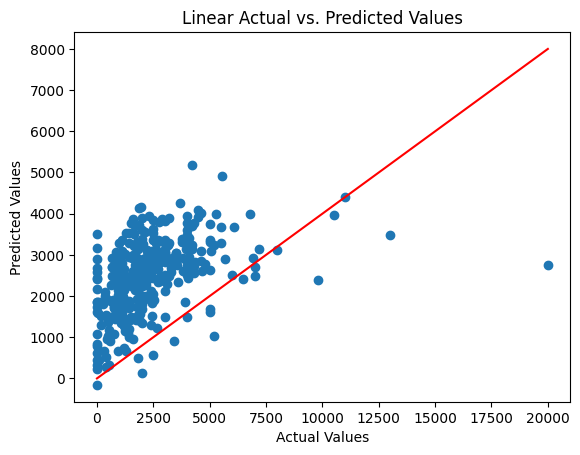

In [30]:
plt.scatter(y_test, y_pred)
plt.plot([0, 20000], [0, 8000], color = 'red')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Linear Actual vs. Predicted Values')
plt.show()

In this specific problem, the RMSE measures the residual between actual and predicted value for how much an observation is behind on rent. R2 score measures the error that can be explained by the model. Based on the graph, the model does an inadequate job predicting past due rent. The model makes the most frequent errors by over-predicting smaller values.

11. Build a Polynomial Regression model.
Real-world relationships are not always perfectly linear. For this model, use PolynomialFeatures(degree=2,
include_bias=False). Apply polynomial transformation to the appropriate numerical variables. Do not
automatically apply polynomial expansion to all one-hot encoded categorical variables.
Train the model and calculate RMSE and R².
Answer:
- Did Polynomial Regression perform better or worse than Linear Regression?
- What does a degree-2 polynomial allow the model to represent that Linear Regression cannot?
- Why could using a very high polynomial degree lead to overfitting?
- Did making the model more complicated automatically make it better?


In [31]:
poly_linear_regression = Pipeline([
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree = 2, include_bias = False)),
    ('linear_model', LinearRegression())
])

poly_linear_regression.fit(X_train, y_train)
y_pred = poly_linear_regression.predict(X_test)

# Calculate RMSE and R2
poly_linear_rmse = root_mean_squared_error(y_test, y_pred)
poly_linear_r2 = r2_score(y_test, y_pred)

print(f'Polynomial RMSE: {poly_linear_rmse}')
print(f'Polynomial R2: {poly_linear_r2}')

Polynomial RMSE: 1985.0054523482347
Polynomial R2: 0.03874963084286376


Polynomial Regression did not perform better than Linear Regression in this senario ((Linear R2: 0.185),(Poly R2: 0.039)). Utilizing degree-2 allows for the model to create new terms to train on up to two features at a time. Using a degree higher than this puts the model at risk for overfitting by creating too many terms to train on; becoming less reliable as a result. Just because a model is more complex, it does not make the model more effective in predicting. Each dataset calls for different approaches.  

12. Build a Ridge Regression model.
Create a Ridge Regression pipeline using the same training and testing data. Choose a reasonable value for
alpha. You may experiment with more than one value.
Calculate RMSE and R².
Answer:
- How does Ridge Regression compare with Linear Regression?
- What does regularization do?
- Why can regularization be useful when a model contains many features?

In [32]:
ridge = make_pipeline(
    preprocessor,
    Ridge(alpha = 0.1)
)
#ridge

ridge = ridge.fit(X_train, y_train)

y_pred = ridge.predict(X_test)

#Calculate RMSE and R2
ridge_rmse = root_mean_squared_error(y_test, y_pred)
ridge_r2 = r2_score(y_test, y_pred)

print(f'Ridge RMSE: {ridge_rmse}')
print(f'Ridge R2: {ridge_r2}')

Ridge RMSE: 1827.6139023932058
Ridge R2: 0.18514184249842403


In [33]:
#Comparing Linear and Ridge
compare1 = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression'],
    'RMSE': [linear_rmse, ridge_rmse],
    'R2': [linear_r2, ridge_r2]
})
compare1

,Model,RMSE,R2
0,Linear Regression,1827.548732,0.185200
1,Ridge Regression,1827.613902,0.185142


Regularization helps make a model better at generalizing by penalizing high errors with alpha. When a model has lots of features like this one, ridge can be helpful to use by reducing the chance of overfitting.

13. Build a Lasso Regression model.
Create a Lasso Regression pipeline using the same training and testing data. Choose a reasonable value for
alpha.
Calculate RMSE and R².
Answer:
- How does Lasso compare with Linear and Ridge Regression?
- What is an important difference between Ridge and Lasso?
- What can happen to some coefficients when Lasso is used?


In [34]:
lasso = make_pipeline(
    preprocessor,
    Lasso(alpha = 5, max_iter = 50000))
#lasso

lasso = lasso.fit(X_train, y_train)
y_pred = lasso.predict(X_test)

#Calculate RMSE and R2
lasso_rmse = root_mean_squared_error(y_test, y_pred)
lasso_r2 = r2_score(y_test, y_pred)

print(f'Lasso RMSE: {lasso_rmse}')
print(f'Lasso R2: {lasso_r2}')

Lasso RMSE: 1825.9406316975221
Lasso R2: 0.18663324515024904


In [35]:
#Comparing Linear, Ridge, and Lasso

compare2 = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'RMSE': [linear_rmse, ridge_rmse, lasso_rmse],
    'R2': [linear_r2, ridge_r2, lasso_r2]
})
compare2

,Model,RMSE,R2
0,Linear Regression,1827.548732,0.185200
1,Ridge Regression,1827.613902,0.185142
2,Lasso Regression,1825.940632,0.186633


Compared to the linear and ridge models, lasso preformed slightly better. The distinction between ridge and lasso is that lasso can perform feature selection. This sets a coefficient to zero, negating uninformative variables in prediction.

14. Compare all four models.

Create a DataFrame containing the test-set results for all four models.

Model RMSE R²
Linear Regression
Polynomial Regression
Ridge Regression
Lasso Regression

Answer:
- Which model has the lowest RMSE?
- Which model has the highest R²?
- Are the differences between the models large or small?
- Did the most complicated model perform the best?
- Which model would you continue investigating? Explain your choice using evidence from your results.



In [47]:
#Feature importance for lasso

# Get the correct feature names out of the fitted ColumnTransformer
feature_names = lasso.named_steps['columntransformer'].get_feature_names_out()

lasso_coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lasso.named_steps['lasso'].coef_
})
lasso_coefficients.sort_values(by = 'Coefficient', ascending = False)

,Feature,Coefficient
16,categorical__eviction_in_progress_Yes,681.293618
3,numerical__monthly_rent,560.468979
7,categorical__employment_status_Employed,412.043478
24,categorical__main_reason_behind_on_rent_Lost a...,323.953857
12,categorical__has_housing_voucher_I don't know,294.147924
28,categorical__main_reason_behind_on_rent_Withhe...,174.779687
4,categorical__household_has_65plus_No,107.727432
0,numerical__adults_in_household,90.991652
2,numerical__monthly_household_income,78.702647
11,categorical__employment_status_Unemployed but ...,72.684290


In [36]:
#Compare linear, poly, ridge, and lasso sort by R2

compare3 = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Lasso Regression'],
    'RMSE': [linear_rmse, poly_linear_rmse, ridge_rmse, lasso_rmse],
    'R2': [linear_r2, poly_linear_r2, ridge_r2, lasso_r2]
})
compare3.sort_values(by = 'R2', ascending = False)


,Model,RMSE,R2
3,Lasso Regression,1825.940632,0.186633
0,Linear Regression,1827.548732,0.185200
2,Ridge Regression,1827.613902,0.185142
1,Polynomial Regression,1985.005452,0.038750


In [37]:
lasso_coefficients = lasso.named_steps['lasso'].coef_
nonzero = np.sum(lasso_coefficients != 0)
total = len(lasso_coefficients)

print('Total poly features:', total)
print('Features kept by lasso:', nonzero)
print( 'Features set to zero:', total - nonzero)

Total poly features: 30
Features kept by lasso: 19
Features set to zero: 11


The model with the lowest RMSE and the highest R2 score is the lasso model. While this model performed the best, the differences between the four models is negligible. While lasso was the most complicated model used, it does not mean that more advanced always gives better results. For this specific data however, I would like to investigate further with more advanced modeling techniques in order to increase the R2 scores and yield more accurate predictions. The model I would like to use further of the four already used would be Lasso because the model penalized more than a third of the variables.

15. Test your selected model on two hypothetical households.
Create TWO new hypothetical cases. Do not copy an actual person from the dataset.

Change several characteristics between the two cases, such as:
- household size
- monthly household income
- employment status
- housing voucher status
- utility situation
- monthly rent

Use your selected pipeline to predict past_due_rent for both cases.
Then explain:
- How are the two households different?
- How different are the predictions?
- Does the difference seem reasonable based on the information you provided?

In [38]:
#Create two new hypothetical observations not currently in the dataset
new_cases = pd.DataFrame({
    'record_id': ['SLCM_9990', 'SLCM_9991'],
    'adults_in_household': [1, 2],
    'children_in_household': [2, 0],
    'household_has_65plus': ['No', 'Yes'],
    'monthly_household_income': [1200.0, 2200.0],
    'income_sources': ['Employment', 'Social Security'],
    'employment_status': [
        'Employed',
        'Unemployed and not looking for work'
    ],
    'has_housing_voucher': ['No', 'Yes'],
    'eviction_in_progress': ['No', 'Yes'],
    'behind_on_utilities': ['Yes', 'No'],
    'main_reason_behind_on_rent': [
        'Lost a job/had hours cut',
        'Unexpected expenses'],
    'intake_quarter': ['2025-Q2', '2025-Q3'],
    'monthly_rent': [950.0, 1100.0],
    'past_due_rent': [1900.0, 3300.0]
})

new_cases.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_9990,1,2,No,1200.0,Employment,Employed,No,No,Yes,Lost a job/had hours cut,2025-Q2,950.0,1900.0
1,SLCM_9991,2,0,Yes,2200.0,Social Security,Unemployed and not looking for work,Yes,Yes,No,Unexpected expenses,2025-Q3,1100.0,3300.0


In [39]:
#Used AI here to process new cases so that they may be put through the model
# Drop non-modeling features that the preprocessor did not train on
new_cases_features = new_cases.drop(columns=['record_id', 'intake_quarter', 'past_due_rent', 'income_sources'], errors='ignore')

# Transform the new cases using the fitted preprocessor
new_cases_preprocessed = preprocessor.transform(new_cases_features)

# Display the preprocessed shape and features
print("Preprocessed shape:", new_cases_preprocessed.shape)

Preprocessed shape: (2, 30)


In [40]:
# Keep only the features that were used to train the model
# Dropping 'record_id', 'intake_quarter', 'past_due_rent', and 'income_sources'
features_to_predict = new_cases.drop(columns=['record_id', 'intake_quarter', 'past_due_rent'], errors='ignore')

# Use the fitted Lasso pipeline to make predictions directly
predictions = lasso.predict(features_to_predict)

# Add the predictions back to the new_cases DataFrame for easy comparison
new_cases_with_predictions = new_cases.copy()
new_cases_with_predictions['predicted_past_due_rent'] = predictions

# Display the results
display(new_cases_with_predictions[['record_id', 'monthly_rent', 'past_due_rent', 'predicted_past_due_rent']])

,record_id,monthly_rent,past_due_rent,predicted_past_due_rent
0,SLCM_9990,950.0,1900.0,2444.236055
1,SLCM_9991,1100.0,3300.0,2264.566568


The primary differences between the two cases are that the first is one employeed adult with two children and the second is two unemployed adults with no children. The first case also is behind on utilities, lower income, and lower rent. Case two has at least one adult over sixty five years old, higher income, and higher rent. The model predicted that case one would be behind more on rent. The values of the predictions were not accurate, but I believe that predicting case one would have more in behind rent is reasonable.

## Part 4 – Interpret the Results (15 points)
16. What did your models tell you?
Write a short interpretation of your overall results. Address:
- Which model performed best on the test data?
- Approximately how large are the model's typical prediction errors?
- Did Polynomial Regression provide a meaningful improvement?
- Did regularization improve the results?
- What does your model appear able to predict reasonably well?
- Where does it appear to struggle?

Use evidence from your RMSE, R², visualizations, and predictions.


In [44]:
#Calculate the average RMSE from linear, poly, ridge, and lasso

average_rmse = (linear_rmse + poly_linear_rmse + ridge_rmse + lasso_rmse) / 4
print(f'Average RMSE: {average_rmse}')

average_R2 = (linear_r2 + poly_linear_r2 + ridge_r2 + lasso_r2) / 4
print(f'Average R2: {average_R2}')

Average RMSE: 1866.5271796290494
Average R2: 0.14893116837531484


The Lasso Regression model performed the best on the data, achieving the highest R2 score of approximately 0.187 and the lowest RMSE of 1,825. The average RMSE is 1866.52. This is relatively high, considering the mean past-due rent is around $2,408.This indicates that predictions can vary substantially from the actual values.

Polynomial Regression did not provide a meaningful improvement. This may be attributed to creating polynomial expansions on one-hot encoded categorical columns, resulting in overfitting to the abundance of columns in the training set. Lasso regularization provided a slight improvement over the standard Multiple Linear Regression model. It also successfully performed feature selection by driving 11 out of 30 coefficients down to zero, simplifying the model structure.

The model is able to pick up on general trends. For example, the model correctly predicted that a family without a housing voucher that is behind on utilities (Case 1) would have a higher past-due rent balance than a household with a voucher that is on time with utility payments (Case 2). The model struggled to predict on much observations with variation in parameters. It significantly over-predicts low values, often predicting ~$2,000+ for households that actually owe very little, and under-predicts the highest-arrears outliers. Overall,the model clustered its predictions around the dataset average behind on rent.

17. What is your overall finding for SLCM?

In 5–8 sentences, explain your analysis as if you were speaking to someone from SLCM who has not taken a
machine-learning course.
Your explanation should address:
- What were you trying to predict?
- What information did you use?
- How successful was the model?
- What is the most important finding?
- Could this type of model potentially be useful for understanding community needs?
- What is one important limitation?

Do not claim that an input variable causes someone to have more or less past-due rent simply because the
model found a relationship.

This model tries to predict the amount a household is behind on rent. Some of the information utilized to attempt this were information on family size and composition, income, rent cost, and reasons for late rent. The model's performance was overall unsucessful. Between the four models, the average rmse was 1866, or the average deviation of the predictions from their actual amount late on rent was $1866. The most important finding from this assignment is the understanding that each situation is very nuanced, and not one variable is key to predicting one's amount late on rent. To improve the understanding of community needs, I believe that there needs to be put forth effort to understand the systemic issues of affordability in the community. Just because one is fully employeed and recieving support, does not decrease the other costs of living.